# Modul 04 — Regularisasi dan Hyperparameter Tuning
**Nama:** Abdillah Fikri Alpome · **NIM:** 123450062 · **Kelas:** RC  
**Tanggal:** 2026-10-27 · **Seed data/model:** 62 · **Device:** CPU

Implementasi diadaptasi dengan izin dari notebook praktikum Fabio Banyu Cyto dan starter resmi DSWorkbench. Kode dan draf analisis dibantu OpenAI Codex; seluruh hasil berkas ini dihitung ulang pada NIM 123450062. Sumber: https://github.com/fabiobanyu/deep-learning-123450104 . Praktikan perlu memahami dan meninjau hasil sebelum pengumpulan.

In [1]:
import copy,hashlib,itertools,json,math,platform,random,time
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch,torchvision
from IPython.display import display,Markdown
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
from torchvision.datasets import FashionMNIST

NAMA = 'Abdillah Fikri Alpome'
NIM = '123450062'
KELAS = 'RC'
SEED=int(NIM[-4:]); SEED_CARI=SEED+1
DEVICE=torch.device('cpu')
torch.set_num_threads(2); torch.use_deterministic_algorithms(True)
torch.set_default_dtype(torch.float32)
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything(SEED)
REPO=next(p for p in [Path('.'),*Path('.').resolve().parents] if (p/'templates/template-metrics.csv').is_file())
MOD=REPO/'notebooks/modul-04'; FIG=MOD/'figures'; SUPPORT=MOD/'hasil'
FIG.mkdir(parents=True,exist_ok=True); SUPPORT.mkdir(parents=True,exist_ok=True)
DATA_ROOT=REPO/'data/raw'; PREFIX=f'M04_{NIM}'
COLS=list(pd.read_csv(REPO/'templates/template-metrics.csv',nrows=0).columns)
ENV=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,torch=torch.__version__,torchvision=torchvision.__version__,device=str(DEVICE),seed=SEED,threads=torch.get_num_threads())
print(ENV)
RUNS=[]; HISTORY={}; MODELS={}; TEST_PASSES=0
def json_default(value):return value.item() if hasattr(value,'item') else str(value)
def save_progress():
    rows=[]
    for r in RUNS:
        notes={k:v for k,v in r.items() if k not in ['train_loss','val_loss','val_acc','test_acc','runtime_s']}
        rows.append(dict(run_id=r['run_id'],module='M04',student_id=NIM,seed=SEED,dataset='Fashion-MNIST',split='stratified train-validation-test',model=r['model'],optimizer=r['optimizer'],learning_rate=r['learning_rate'],batch_size=r['batch_size'],epochs=r['epochs_completed'],train_loss=r['train_loss'],val_loss=r['val_loss'],val_metric=r['val_acc'],test_metric=r.get('test_acc',''),parameters=r['parameters'],trainable_parameters=r['parameters'],runtime_seconds=r['runtime_s'],device=str(DEVICE),notes=json.dumps(notes,default=json_default,ensure_ascii=False)))
    pd.DataFrame(rows,columns=COLS).to_csv(MOD/f'{PREFIX}_metrics.csv',index=False)
    pd.DataFrame([dict(run_id=rid,**e) for rid,h in HISTORY.items() for e in h]).to_csv(SUPPORT/f'{PREFIX}_history.csv',index=False)
def show_figure(fig,name):
    fig.tight_layout(); fig.savefig(FIG/name,dpi=160,bbox_inches='tight'); plt.show()


{'python': '3.14.7', 'numpy': '2.5.3', 'pandas': '3.0.5', 'torch': '2.14.0+cpu', 'torchvision': '0.29.0+cpu', 'device': 'cpu', 'seed': 62, 'threads': 2}


## A. Pre-lab dan protokol anti-kebocoran
1. Overfitting tampak ketika loss train terus turun sementara loss validasi naik; underfitting ketika keduanya masih tinggi.
2. Dropout dimatikan melalui model.eval() agar evaluasi deterministik tanpa mask acak; torch.no_grad() hanya mematikan pencatatan gradien.
3. Weight decay pada Adam menambahkan komponen penalti L2 pada gradien, sehingga menekan besarnya bobot; loss evaluasi tetap cross-entropy murni.
4. Pemilihan lewat test menjadikan test bagian proses tuning sehingga perkiraan generalisasinya bias.

**Hipotesis sebelum run:** baseline 512–512 pada 3000 citra dan 30 epoch akan overfit. Dropout 0,5 diperkirakan menekan gap tetapi memperlambat penyesuaian; dropout 0,2 diperkirakan menurunkan train loss lebih cepat daripada 0,5. Early stopping diperkirakan menghentikan kenaikan loss validasi. Hipotesis ini disimpan sebelum eksekusi, bukan disimpulkan dari hasil lama.

Semua strategi berasal dari baseline Adam 0,001, batch 128, maksimal 30 epoch. Dropout, weight decay dan early stopping diuji terpisah. Random search mengambil 12 kombinasi unik dari 81 memakai seed 63. Trial dan refit final memakai pemulihan checkpoint validasi terbaik; exercise dropout 0,2 tidak menjadi kandidat pemilihan final. Dataset test belum dibuat sampai tahap final.

In [2]:
prediction=dict(written_at=datetime.now().isoformat(timespec='seconds'),seed=SEED,seed_search=SEED_CARI,
    text="Baseline diperkirakan overfit; dropout 0.5 mengurangi gap tetapi lebih lambat; dropout 0.2 diperkirakan menurunkan train loss lebih cepat.")
(SUPPORT/'prediksi-sebelum-run.json').write_text(json.dumps(prediction,ensure_ascii=False,indent=2),encoding='utf-8')
full_train=FashionMNIST(root=DATA_ROOT,train=True,download=False)
labels=full_train.targets.numpy()
idx_train,idx_val=train_test_split(np.arange(len(labels)),train_size=3000,test_size=3000,stratify=labels,random_state=SEED)
assert not set(idx_train)&set(idx_val)
Xtrain=full_train.data[idx_train].float().unsqueeze(1)/255.0
Xval=full_train.data[idx_val].float().unsqueeze(1)/255.0
MEAN,STD=Xtrain.mean(),Xtrain.std()
assert STD>0
ds_latih=TensorDataset((Xtrain-MEAN)/STD,full_train.targets[idx_train])
ds_val=TensorDataset((Xval-MEAN)/STD,full_train.targets[idx_val])
assert len(ds_latih)==3000 and len(ds_val)==3000
assert np.bincount(labels[idx_train]).min()==300
manifest=pd.concat([pd.DataFrame(dict(index=idx_train,label=labels[idx_train],split='train')),pd.DataFrame(dict(index=idx_val,label=labels[idx_val],split='validation'))])
manifest.to_csv(SUPPORT/'split-manifest.csv',index=False)
def normalkan(x):return (x-MEAN)/STD
def loader(ds,batch,acak=False):
    return DataLoader(ds,batch_size=batch,shuffle=acak,generator=torch.Generator().manual_seed(SEED),num_workers=0)
@torch.no_grad()
def evaluasi(model,ds):
    model.eval(); loss_sum=correct=0
    for x,y in loader(ds,512):
        x,y=x.to(DEVICE),y.to(DEVICE); logits=model(x)
        loss_sum+=nn.functional.cross_entropy(logits,y,reduction='sum').item()
        correct+=(logits.argmax(1)==y).sum().item()
    return loss_sum/len(ds),correct/len(ds)
print('Train/validation:',len(ds_latih),len(ds_val),'mean/std:',float(MEAN),float(STD))
print('Kelas train:',np.bincount(labels[idx_train]).tolist())


Train/validation: 3000 3000 mean/std: 0.28974878787994385 0.35541725158691406
Kelas train: [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]


In [3]:
BATCH,EPOCH=128,30
def buat_model(hidden=512,dropout=0.0):
    seed_everything(SEED)
    return nn.Sequential(nn.Flatten(),nn.Linear(784,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,10)).to(DEVICE)
assert sum(p.numel() for p in buat_model().parameters())==669706
def jalankan(hidden=512,dropout=0.,weight_decay=0.,lr=1e-3,epoch=EPOCH,sabar=None,label='baseline',group='regularisasi'):
    assert label not in HISTORY
    model=buat_model(hidden,dropout);opt=torch.optim.Adam(model.parameters(),lr=lr,weight_decay=weight_decay)
    train_loader=loader(ds_latih,BATCH,True);history=[]
    best_loss=float('inf');best_state=None;best_epoch=0;wait=0;updates=0;status='ok';started=time.perf_counter()
    for e in range(1,epoch+1):
        model.train();online=seen=0;epoch_start=time.perf_counter()
        for x,y in train_loader:
            x,y=x.to(DEVICE),y.to(DEVICE);opt.zero_grad(set_to_none=True)
            loss=nn.functional.cross_entropy(model(x),y)
            if not torch.isfinite(loss):status=f'failed_nonfinite_epoch_{e}';break
            loss.backward();opt.step();updates+=1;online+=loss.item()*len(y);seen+=len(y)
        if not seen:break
        tr,tr_acc=evaluasi(model,ds_latih);va,va_acc=evaluasi(model,ds_val)
        history.append(dict(epoch=e,train_loss=tr,val_loss=va,train_acc=tr_acc,val_acc=va_acc,gap=va-tr,online_train_loss=online/seen,seconds=time.perf_counter()-epoch_start))
        if va<best_loss:best_loss=va;best_state=copy.deepcopy(model.state_dict());best_epoch=e;wait=0
        else:wait+=1
        print(f'[{label}] epoch {e}/{epoch} train={tr:.5f} val={va:.5f} acc={va_acc:.4f}',flush=True)
        if status!='ok':break
        if sabar is not None and wait>=sabar:status='early_stopped';break
    assert best_state is not None
    model.load_state_dict(best_state)
    tr,tr_acc=evaluasi(model,ds_latih);va,va_acc=evaluasi(model,ds_val)
    r=dict(run_id=label,optimizer='Adam',learning_rate=lr,batch_size=BATCH,hidden=hidden,dropout=dropout,weight_decay=weight_decay,patience=sabar,seed_search=SEED_CARI,epochs_planned=epoch,epochs_completed=len(history),best_epoch=best_epoch,n_update=updates,model=f'FNN(784-{hidden}-{hidden}-10)',parameters=sum(p.numel() for p in model.parameters()),train_loss=tr,train_acc=tr_acc,val_loss=va,val_acc=va_acc,gap=va-tr,val_loss_last=history[-1]['val_loss'],train_loss_last=history[-1]['train_loss'],gap_last=history[-1]['gap'],weight_norm=math.sqrt(sum(p.detach().pow(2).sum().item() for p in model.parameters() if p.ndim>1)),runtime_s=time.perf_counter()-started,status=status,group=group)
    r['runtime_per_epoch_s']=r['runtime_s']/len(history)
    RUNS.append(r);HISTORY[label]=history;MODELS[label]=best_state;save_progress()
    return r
print('Baseline parameter:',669706)


Baseline parameter: 669706


[baseline] epoch 1/30 train=0.67241 val=0.71524 acc=0.7480


[baseline] epoch 2/30 train=0.57899 val=0.64054 acc=0.7503


[baseline] epoch 3/30 train=0.40521 val=0.49941 acc=0.8187


[baseline] epoch 4/30 train=0.37019 val=0.49127 acc=0.8200


[baseline] epoch 5/30 train=0.32066 val=0.47672 acc=0.8293


...

[baseline] epoch 26/30 train=0.02535 val=0.72106 acc=0.8450


[baseline] epoch 27/30 train=0.04747 val=0.78960 acc=0.8393


[baseline] epoch 28/30 train=0.03168 val=0.75744 acc=0.8480


[baseline] epoch 29/30 train=0.07861 val=0.79360 acc=0.8303


[baseline] epoch 30/30 train=0.02213 val=0.69845 acc=0.8513


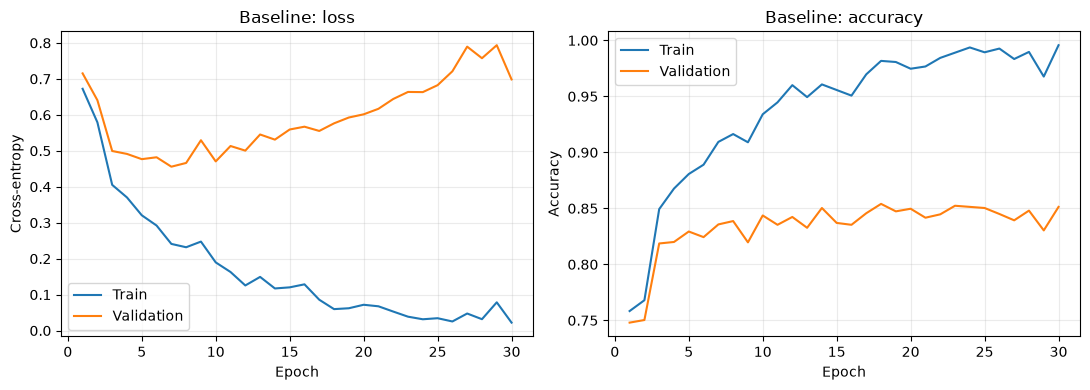

Epoch terbaik: 7 loss terbaik: 0.4557655944824219 loss epoch 30: 0.6984541422526042 gap epoch terakhir: 0.6763226801554362


In [4]:
baseline=jalankan()
h=HISTORY['baseline']
fig,axs=plt.subplots(1,2,figsize=(11,4))
for key,label in [('train_loss','Train'),('val_loss','Validation')]:axs[0].plot([e['epoch'] for e in h],[e[key] for e in h],label=label)
for key,label in [('train_acc','Train'),('val_acc','Validation')]:axs[1].plot([e['epoch'] for e in h],[e[key] for e in h],label=label)
axs[0].set(title='Baseline: loss',xlabel='Epoch',ylabel='Cross-entropy');axs[1].set(title='Baseline: accuracy',xlabel='Epoch',ylabel='Accuracy')
for ax in axs:ax.legend();ax.grid(alpha=.25)
show_figure(fig,'baseline.png')
print('Epoch terbaik:',baseline['best_epoch'],'loss terbaik:',baseline['val_loss'],'loss epoch 30:',baseline['val_loss_last'],'gap epoch terakhir:',baseline['gap_last'])
assert max(e['val_loss'] for e in h[baseline['best_epoch']:])>baseline['val_loss'],'Jika tidak naik, laporkan keterbatasan tanpa mengubah protokol'


[dropout_0.5] epoch 1/30 train=0.67342 val=0.69280 acc=0.7203


[dropout_0.5] epoch 2/30 train=0.57142 val=0.60649 acc=0.7733


[dropout_0.5] epoch 3/30 train=0.47063 val=0.51256 acc=0.8127


[dropout_0.5] epoch 4/30 train=0.43825 val=0.50125 acc=0.8140


[dropout_0.5] epoch 5/30 train=0.43869 val=0.51055 acc=0.8163


...

[early_stopping_patience_5] epoch 9/30 train=0.24747 val=0.52931 acc=0.8197


[early_stopping_patience_5] epoch 10/30 train=0.18961 val=0.47046 acc=0.8437


[early_stopping_patience_5] epoch 11/30 train=0.16293 val=0.51327 acc=0.8353


[early_stopping_patience_5] epoch 12/30 train=0.12549 val=0.50044 acc=0.8423


,run_id,optimizer,learning_rate,batch_size,hidden,dropout,weight_decay,patience,seed_search,epochs_planned,...,val_acc,gap,val_loss_last,train_loss_last,gap_last,weight_norm,runtime_s,status,group,runtime_per_epoch_s
0,baseline,Adam,0.001,128,512,0.0,0.000,NaN,63,30,...,0.835667,0.214747,0.698454,0.022131,0.676323,21.211344,7.842051,ok,regularisasi,0.261402
1,dropout_0.5,Adam,0.001,128,512,0.5,0.000,NaN,63,30,...,0.853333,0.265440,0.524726,0.136846,0.387880,25.339576,9.078276,ok,regularisasi,0.302609
2,weight_decay_1e-3,Adam,0.001,128,512,0.0,0.001,NaN,63,30,...,0.839333,0.199436,0.580117,0.041515,0.538602,17.449750,7.972205,ok,regularisasi,0.265740
3,early_stopping_patience_5,Adam,0.001,128,512,0.0,0.000,5.0,63,30,...,0.835667,0.214747,0.500441,0.125491,0.374950,21.211344,3.200251,early_stopped,regularisasi,0.266688


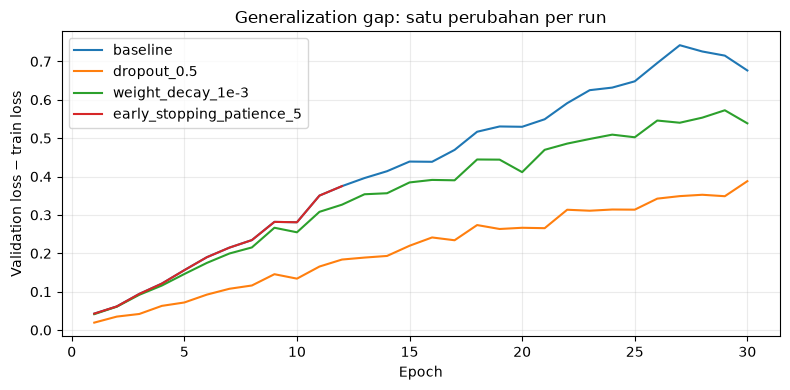

In [5]:
regularisasi=[baseline]
regularisasi.append(jalankan(dropout=.5,label='dropout_0.5'))
regularisasi.append(jalankan(weight_decay=1e-3,label='weight_decay_1e-3'))
regularisasi.append(jalankan(sabar=5,label='early_stopping_patience_5'))
assert len(regularisasi)==4
display(pd.DataFrame(regularisasi))
fig,ax=plt.subplots(figsize=(8,4))
for r in regularisasi:
    h=HISTORY[r['run_id']];ax.plot([e['epoch'] for e in h],[e['gap'] for e in h],label=r['run_id'])
ax.set(title='Generalization gap: satu perubahan per run',xlabel='Epoch',ylabel='Validation loss − train loss');ax.legend();ax.grid(alpha=.25)
show_figure(fig,'gap-regularisasi.png')


## Latihan mandiri: dropout 0,2 versus 0,5
Prediksi sebelum run sudah tercatat pada A dan prediksi-sebelum-run.json: dropout 0,2 diperkirakan lebih cepat menurunkan train loss, sedangkan dropout 0,5 memberi regularisasi lebih kuat. Perbandingan memakai checkpoint terbaik yang dipilih dengan aturan identik; grafik seluruh epoch juga ditampilkan. Accuracy test tidak digunakan.

[dropout_0.2] epoch 1/30 train=0.66398 val=0.70047 acc=0.7380


[dropout_0.2] epoch 2/30 train=0.53926 val=0.59223 acc=0.7817


[dropout_0.2] epoch 3/30 train=0.41465 val=0.49065 acc=0.8217


[dropout_0.2] epoch 4/30 train=0.36669 val=0.46544 acc=0.8260


[dropout_0.2] epoch 5/30 train=0.37426 val=0.50383 acc=0.8187


...

[dropout_0.2] epoch 26/30 train=0.05859 val=0.61583 acc=0.8480


[dropout_0.2] epoch 27/30 train=0.07594 val=0.69080 acc=0.8367


[dropout_0.2] epoch 28/30 train=0.04269 val=0.62929 acc=0.8537


[dropout_0.2] epoch 29/30 train=0.04633 val=0.68181 acc=0.8437


[dropout_0.2] epoch 30/30 train=0.06113 val=0.73119 acc=0.8443


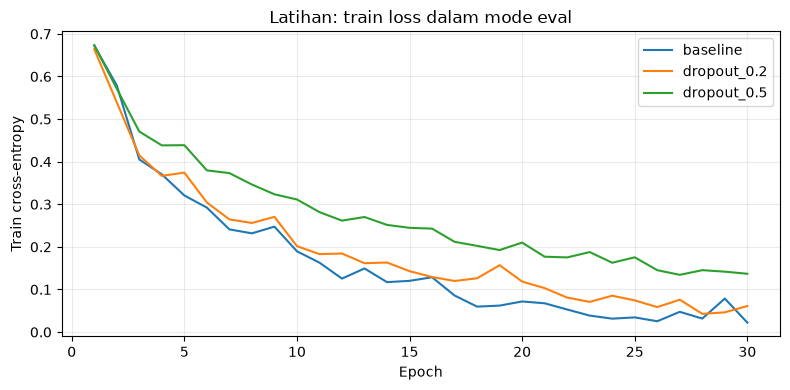

In [6]:
dropout02=jalankan(dropout=.2,label='dropout_0.2',group='latihan')
fig,ax=plt.subplots(figsize=(8,4))
for rid in ['baseline','dropout_0.2','dropout_0.5']:
    h=HISTORY[rid];ax.plot([e['epoch'] for e in h],[e['train_loss'] for e in h],label=rid)
ax.set(title='Latihan: train loss dalam mode eval',xlabel='Epoch',ylabel='Train cross-entropy');ax.legend();ax.grid(alpha=.25)
show_figure(fig,'latihan-dropout.png')


In [7]:
SPACE={'hidden':[64,128,256],'dropout':[0.,.2,.5],'weight_decay':[0.,1e-4,1e-3],'learning_rate':[1e-4,3e-4,1e-3]}
combinations=[dict(zip(SPACE.keys(),vals)) for vals in itertools.product(*SPACE.values())]
assert len(combinations)==81
chosen=np.random.default_rng(SEED_CARI).choice(len(combinations),size=12,replace=False)
trials=[]
for number,index in enumerate(chosen,1):
    cfg=combinations[int(index)].copy();cfg['lr']=cfg.pop('learning_rate')
    r=jalankan(**cfg,sabar=5,label=f'random_{number:02d}',group='random_search')
    r['combination_index']=int(index);trials.append(r)
assert len(trials)==12 and len(set(int(i) for i in chosen))==12
display(pd.DataFrame(trials).sort_values('val_loss'))
best_trial=min(trials,key=lambda r:r['val_loss'])
cfg=dict(hidden=best_trial['hidden'],dropout=best_trial['dropout'],weight_decay=best_trial['weight_decay'],lr=best_trial['learning_rate'],sabar=5,label='final_retrain',group='final')
final=jalankan(**cfg)
assert abs(final['val_loss']-best_trial['val_loss'])<1e-10
final_model=buat_model(final['hidden'],final['dropout']);final_model.load_state_dict(MODELS['final_retrain'])
assert len(RUNS)==18
print('Pilihan terkunci sebelum test:',best_trial['run_id'],cfg)


[random_01] epoch 1/30 train=1.72769 val=1.74434 acc=0.4907


[random_01] epoch 2/30 train=1.20752 val=1.24293 acc=0.6403


[random_01] epoch 3/30 train=0.93357 val=0.96774 acc=0.7117


[random_01] epoch 4/30 train=0.81273 val=0.84086 acc=0.7207

[random_01] epoch 5/30 train=0.72797 val=0.75501 acc=0.7387

...

[final_retrain] epoch 12/30 train=0.20572 val=0.44252 acc=0.8490


[final_retrain] epoch 13/30 train=0.23411 val=0.47674 acc=0.8403


[final_retrain] epoch 14/30 train=0.18949 val=0.44673 acc=0.8517


[final_retrain] epoch 15/30 train=0.17201 val=0.47496 acc=0.8460


Pilihan terkunci sebelum test: random_11 {'hidden': 256, 'dropout': 0.2, 'weight_decay': 0.0001, 'lr': 0.001, 'sabar': 5, 'label': 'final_retrain', 'group': 'final'}


## Evaluasi akhir: satu lintasan test
Seluruh konfigurasi dikunci berdasarkan validation loss. Dataset test resmi baru dibuka di bawah; loss, accuracy dan confusion matrix dihitung dari satu koleksi logits yang sama, bukan beberapa evaluasi terpisah. Tidak ada tuning setelah melihat hasil test.

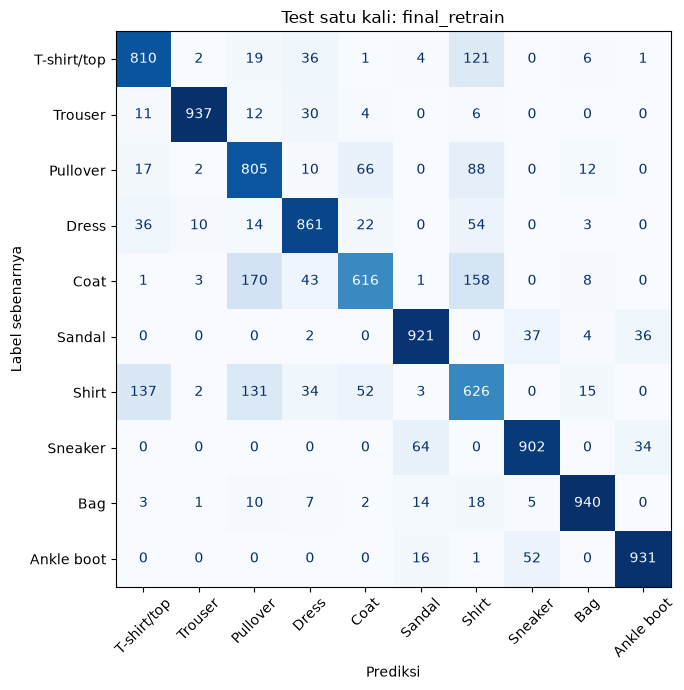

FINAL: final_retrain test_loss= 0.46557270431518555 test_acc= 0.8349 test_passes= 1


In [8]:
assert TEST_PASSES==0
TEST_PASSES+=1
official_test=FashionMNIST(root=DATA_ROOT,train=False,download=False)
Xt=normalkan(official_test.data.float().unsqueeze(1)/255.)
ds_uji=TensorDataset(Xt,official_test.targets)
@torch.no_grad()
def test_once(model):
    model.eval();loss_sum=0;truth=[];pred=[]
    for x,y in loader(ds_uji,512):
        x,y=x.to(DEVICE),y.to(DEVICE);logits=model(x)
        loss_sum+=nn.functional.cross_entropy(logits,y,reduction='sum').item()
        truth.extend(y.cpu().tolist());pred.extend(logits.argmax(1).cpu().tolist())
    return loss_sum/len(ds_uji),np.array(truth),np.array(pred)
test_loss,truth,pred=test_once(final_model)
test_acc=float((truth==pred).mean());final['test_acc']=test_acc
cm=confusion_matrix(truth,pred,labels=range(10))
CLASS_NAMES=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
fig,ax=plt.subplots(figsize=(9,7))
ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,xticks_rotation=45,cmap='Blues',colorbar=False)
ax.set(title='Test satu kali: '+final['run_id'],xlabel='Prediksi',ylabel='Label sebenarnya')
show_figure(fig,'confusion-test.png')
pd.DataFrame(dict(index=np.arange(len(truth)),true=truth,predicted=pred)).to_csv(SUPPORT/'test-predictions.csv',index=False)
save_progress()
summary=dict(name=NAMA,nim=NIM,class_name=KELAS,date=datetime.now().date().isoformat(),environment=ENV,seed=SEED,seed_search=SEED_CARI,normalization=dict(mean=float(MEAN),std=float(STD)),split=dict(train=len(ds_latih),validation=len(ds_val),test=len(ds_uji)),prediction=prediction,runs=RUNS,selected_run=final['run_id'],test_loss=test_loss,test_accuracy=test_acc,test_passes=TEST_PASSES,confusion_matrix=cm.tolist())
(SUPPORT/f'{PREFIX}_results.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=json_default),encoding='utf-8')
print('FINAL:',final['run_id'],'test_loss=',test_loss,'test_acc=',test_acc,'test_passes=',TEST_PASSES)
assert TEST_PASSES==1 and cm.sum()==10000


## Catatan interpretasi dan reproduksi
Semua angka tersedia pada metrics dan hasil/riwayat per epoch. Seluruh run, termasuk konfigurasi buruk, tetap dicatat. Template 20 kolom dipertahankan; hyperparameter tambahan, jumlah update, status, gradien atau gap disimpan pada notes JSON. Laporan dan latihan pendamping disusun dari hasil aktual, dengan prediksi yang tercatat sebelum training.

Referensi: materi dan starter resmi DSWorkbench; adaptasi notebook Fabio Banyu Cyto dengan izin; dokumentasi PyTorch optimizers dan torchvision FashionMNIST. Bantuan OpenAI Codex dicantumkan untuk implementasi dan draf pembahasan. Praktikan meninjau hasil dan pernyataan orisinalitas sebelum pengumpulan.

## Pembahasan berdasarkan eksekusi ini

**1.** Baseline menunjukkan validation loss minimum 0.455766 pada epoch 7, lalu lebih tinggi sesudahnya, misalnya epoch 8. Pada epoch terakhir loss validasi 0.698454 dan gap 0.676323; ketidakseimbangan train-validation ini menjadi bukti overfitting.

**2.** Di antara baseline dan tiga strategi terpisah, gap checkpoint terkecil dimiliki weight_decay_1e-3 sebesar 0.199436, sedangkan validation loss terendah dimiliki dropout_0.5 sebesar 0.442318. Gap kecil saja dapat muncul karena underfitting; karena itu tetap perlu melihat kedua loss.

**3.** Dalam percobaan ini pemenang random_11 memang memakai jumlah parameter maksimum dalam ruang yang dicoba, yaitu 269,322. Namun trial lain dengan kapasitas sama, misalnya random_09, memperoleh loss 0.457734, dibanding 0.430266 pada pemenang. Jadi jumlah parameter saja belum menentukan peringkat.

**4.** Secara deskriptif, learning_rate memiliki rentang rerata validation loss antarkelompok terbesar: nilai 0.0001 memberi rerata 0.543574, sedangkan 0.001 memberi 0.439228. Namun hanya 12 dari 81 kombinasi diuji dan jumlah anggota tiap kelompok tidak seimbang; faktor lain ikut berubah, sehingga ini bukan bukti pengaruh kausal tunggal.

**5.** Model final memiliki validation loss 0.430266 dan test loss 0.465573, sehingga test minus validation adalah +0.035307. Ini menggambarkan perbedaan hasil pada dua split untuk model terpilih, bukan alasan menyesuaikan hyperparameter setelah melihat test; hanya satu lintasan test dilakukan.